# Unit 2 seminar: exploratory data analysis on Auto-mpg

**Task (from the seminar booklet):** after the module's EDA tutorial, do a similar EDA on the Auto-mpg dataset:
1. identify missing values
2. estimate skewness and kurtosis
3. correlation heat map
4. scatter plots for different parameters
5. replace categorical values with numerical values (America 1, Europe 2, etc.)

The module's tutorial (house prices) uses a few functions that have since been removed from the libraries,
such as `np.object` and `sns.factorplot`. So I've used the same methods here in current syntax rather than
re-running the tutorial as-is.

In [1]:
import pandas as pd                                  # tables
import numpy as np                                   # maths
import matplotlib.pyplot as plt                      # plotting
import seaborn as sns                                # nicer statistical plots, used by the module's tutorial
import missingno as msno                             # missing-value plots, used by the module's tutorial

df = pd.read_csv("auto-mpg.csv")                     # load the module's Auto-mpg file
print(df.shape)                                      # (rows, columns)
df.head()                                            # first five rows, to see what the data looks like

(398, 9)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino


In [2]:
df.dtypes  # the type pandas gave each column: a number column loaded as 'object' (text) is a warning sign

mpg             float64
cylinders         int64
displacement    float64
horsepower       object
weight            int64
acceleration    float64
model year        int64
origin            int64
car name         object
dtype: object

## 1. Missing values

In [3]:
print("Missing values according to isna():")        # the usual first check
print(df.isna().sum().to_string())                   # count of blank cells per column

Missing values according to isna():
mpg             0
cylinders       0
displacement    0
horsepower      0
weight          0
acceleration    0
model year      0
origin          0
car name        0


That says there are none. But `horsepower` came in as text (`object`) when it should be a number, which is a
clue that something non-numeric is hiding in it.

In [4]:
bad = df[pd.to_numeric(df["horsepower"], errors="coerce").isna()]   # rows where horsepower can't be read as a number
print(f"{len(bad)} rows where horsepower isn't a number. The values are: {bad['horsepower'].unique()}")  # how many, and what the bad values are
bad[["car name", "cylinders", "displacement", "horsepower", "weight", "mpg"]]   # show those cars

6 rows where horsepower isn't a number. The values are: ['?']


,car name,cylinders,displacement,horsepower,weight,mpg
32,ford pinto,4,98.0,?,2046,25.0
126,ford maverick,6,200.0,?,2875,21.0
330,renault lecar deluxe,4,85.0,?,1835,40.9
336,ford mustang cobra,4,140.0,?,2905,23.6
354,renault 18i,4,100.0,?,2320,34.5
374,amc concord dl,4,151.0,?,3035,23.0


Missing values now: {'horsepower': 6}


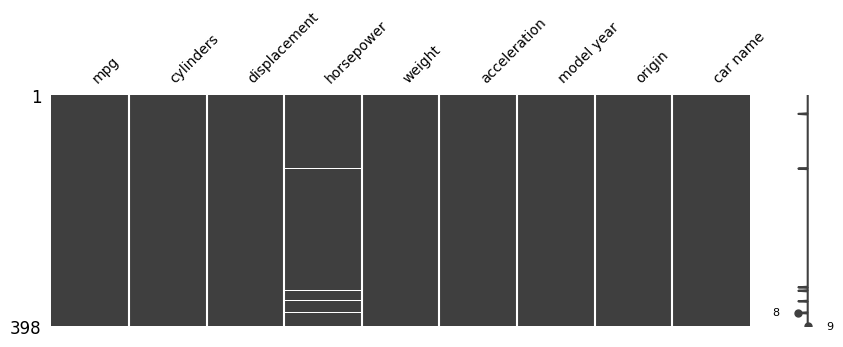

In [5]:
# Convert '?' to a real missing value so pandas can see it
df["horsepower"] = pd.to_numeric(df["horsepower"], errors="coerce")   # anything that isn't a number becomes NaN
print("Missing values now:", df.isna().sum()[lambda s: s > 0].to_dict())   # only columns that have gaps
msno.matrix(df, figsize=(10, 3), fontsize=10)        # picture of where the gaps are: white lines are missing values
plt.show()                                           # draw

### What to do with the six gaps

In [6]:
# Option A: drop the 6 rows. Option B: fill each one with the median horsepower of cars with the same
# number of cylinders, since cylinders and horsepower are closely linked.
cyl_median = df.groupby("cylinders")["horsepower"].transform("median")   # median horsepower for each car's cylinder group
filled = df["horsepower"].fillna(cyl_median)         # use it only where horsepower is missing
print("Filled values:", filled[df["horsepower"].isna()].round(0).tolist())   # what the six cars got
print(f"Overall median would have given {df['horsepower'].median():.0f} for every car.")   # the simpler alternative
df["horsepower"] = filled                            # keep the cylinder-based fill

Filled values: [78.0, 100.0, 78.0, 78.0, 78.0, 78.0]
Overall median would have given 94 for every car.


## 2. Skewness and kurtosis

- **Skewness** measures how lopsided a distribution is. 0 is symmetric. Positive means a long tail to the
  right, a few unusually high values.
- **Kurtosis** (pandas reports *excess* kurtosis) measures how heavy the tails are compared with a normal
  curve. 0 is normal-like. Negative means flatter, with fewer extreme values.

In [7]:
num = df.select_dtypes(include="number")             # only the numeric columns
shape = pd.DataFrame({"skewness": num.skew(), "kurtosis": num.kurt()}).round(2)   # both measures, one row per column
shape                                                # show the table

,skewness,kurtosis
mpg,0.46,-0.51
cylinders,0.53,-1.38
displacement,0.72,-0.75
horsepower,1.11,0.75
weight,0.53,-0.79
acceleration,0.28,0.42
model year,0.01,-1.18
origin,0.92,-0.82


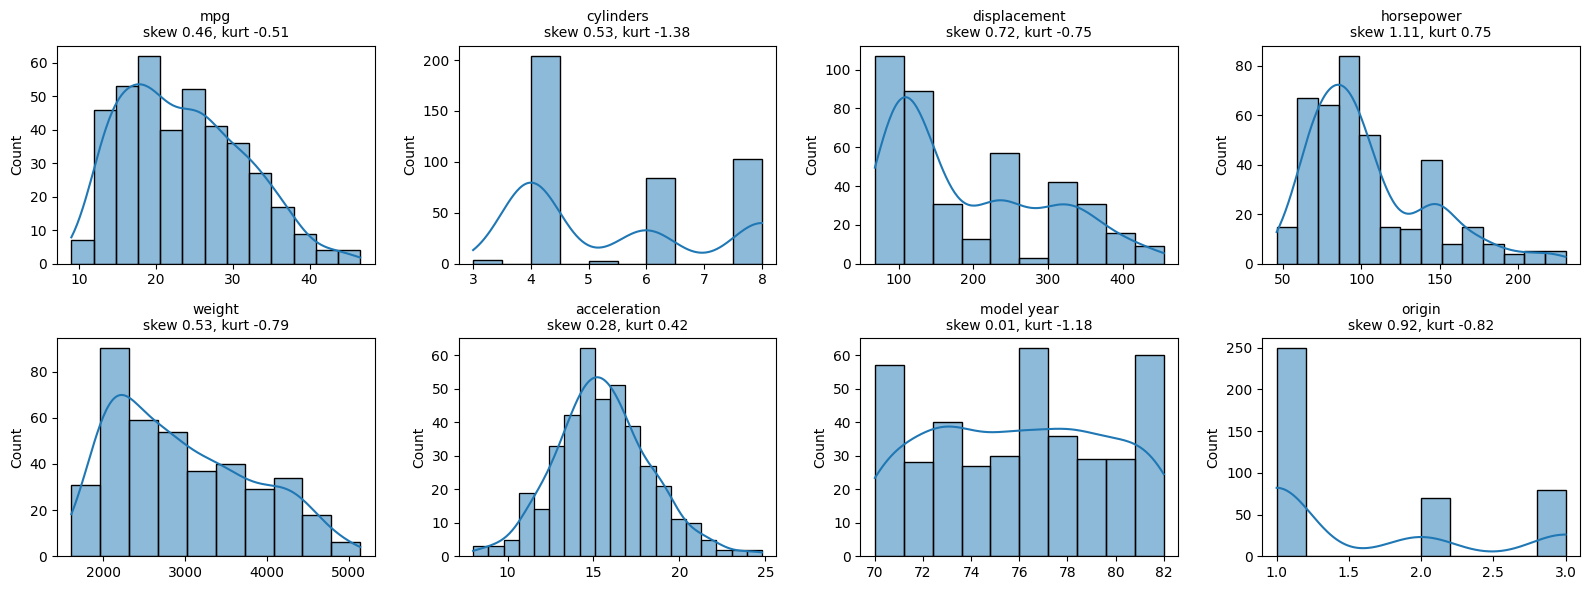

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(16, 6))      # a 2 x 4 grid of plots, one per numeric column
for ax, col in zip(axes.ravel(), num.columns):       # pair each plot with a column
    sns.histplot(num[col], kde=True, ax=ax)          # histogram with a smoothed curve on top
    ax.set_title(f"{col}\nskew {num[col].skew():.2f}, kurt {num[col].kurt():.2f}", fontsize=10)   # numbers in the title
    ax.set_xlabel("")                                # the title already names the column
plt.tight_layout(); plt.show()                       # draw

## 3. Correlation heat map

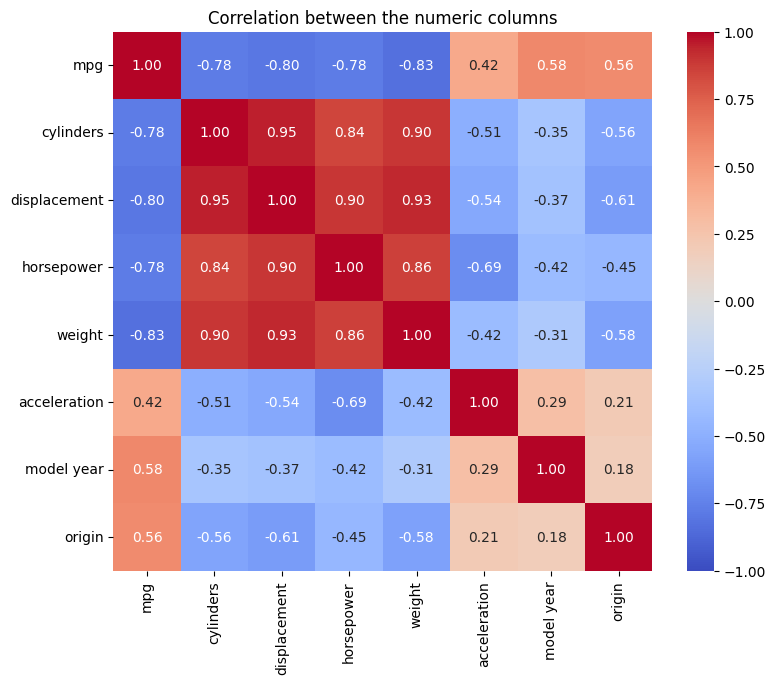

weight         -0.83
displacement   -0.80
horsepower     -0.78
cylinders      -0.78
acceleration    0.42
origin          0.56
model year      0.58


In [9]:
corr = num.corr()                                    # Pearson correlation between every pair of numeric columns
plt.figure(figsize=(9, 7))                           # one square-ish plot
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)   # red = positive, blue = negative
plt.title("Correlation between the numeric columns"); plt.show()  # title and draw
print(corr["mpg"].drop("mpg").sort_values().round(2).to_string())   # just the correlations with mpg, as text

## 4. Scatter plots

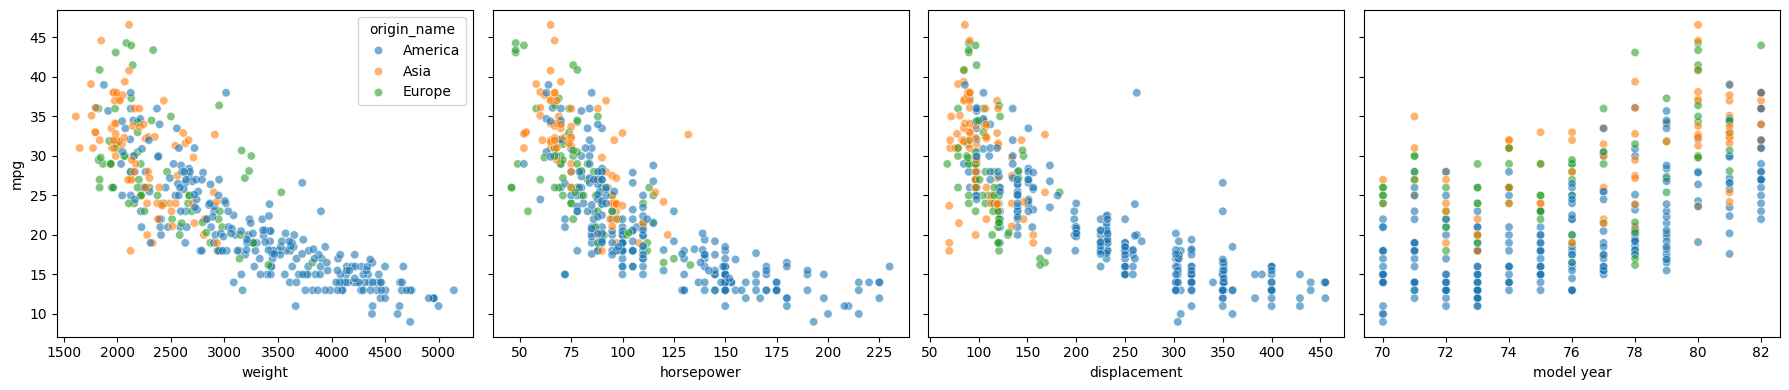

In [10]:
origin_names = {1: "America", 2: "Europe", 3: "Asia"}   # what the origin codes mean
df["origin_name"] = df["origin"].map(origin_names)   # a readable version for the plot legend

fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)   # four plots in a row, sharing the mpg axis
for ax, col in zip(axes, ["weight", "horsepower", "displacement", "model year"]):   # the four most related columns
    sns.scatterplot(data=df, x=col, y="mpg", hue="origin_name", alpha=0.6, ax=ax, legend=(col == "weight"))   # coloured by origin
plt.tight_layout(); plt.show()                       # draw

In [11]:
# Is the mpg-horsepower relationship really a straight line?
from scipy.stats import pearsonr, spearmanr          # Pearson looks for a straight line, Spearman only for rank order
for col in ["weight", "horsepower", "displacement"]:   # the three size columns
    print(f"mpg vs {col:<12} Pearson {pearsonr(df[col], df['mpg'])[0]:.3f}   Spearman {spearmanr(df[col], df['mpg'])[0]:.3f}")  # both correlations side by side

mpg vs weight       Pearson -0.832   Spearman -0.875
mpg vs horsepower   Pearson -0.776   Spearman -0.851
mpg vs displacement Pearson -0.804   Spearman -0.856


## 5. Categorical values to numbers

In [12]:
print("origin is already stored as numbers:", sorted(df["origin"].unique().tolist()))   # the codes in the file
print(df["origin_name"].value_counts().to_string())  # how many cars from each region

origin is already stored as numbers: [1, 2, 3]
origin_name
America    249
Asia        79
Europe      70


The task's mapping (America 1, Europe 2...) is already done in this file. The question worth asking is whether
1/2/3 is the *right* way to store it. Origin has no order: Asia isn't "more" than Europe. Storing it as 1, 2, 3
tells a model there is an order and that the gaps are equal. One-hot encoding, one yes/no column per region,
avoids that. Below I test whether it makes a difference.

In [13]:
from sklearn.linear_model import LinearRegression    # a simple straight-line model
from sklearn.model_selection import cross_val_score, KFold   # cross-validation tools

y = df["mpg"]                                        # what we're predicting
as_number = df[["origin"]]                           # origin as one column of 1/2/3
one_hot = pd.get_dummies(df["origin_name"], prefix="origin", dtype=int)   # origin as three yes/no columns
print(one_hot.head(3))                               # show what one-hot looks like
for label, X in [("origin as 1/2/3", as_number), ("origin one-hot", one_hot)]:   # compare the two encodings
    # shuffle=True matters: the file is sorted by model year, and mpg rises over the years
    r2 = cross_val_score(LinearRegression(), X, y, cv=KFold(5, shuffle=True, random_state=0), scoring="r2").mean()  # average R² over 5 shuffled folds
    print(f"{label:<17} cross-validated R² predicting mpg from origin alone: {r2:.3f}")  # one line per encoding

# The same test without shuffling: each fold becomes a block of model years
r2_unshuffled = cross_val_score(LinearRegression(), one_hot, y, cv=5, scoring="r2").mean()  # cv=5 with no shuffle = folds in file order
print(f"\nSame one-hot model WITHOUT shuffling the folds: R² {r2_unshuffled:.3f}")  # the unshuffled result, for comparison

   origin_America  origin_Asia  origin_Europe
0               1            0              0
1               1            0              0
2               1            0              0
origin as 1/2/3   cross-validated R² predicting mpg from origin alone: 0.311
origin one-hot    cross-validated R² predicting mpg from origin alone: 0.324

Same one-hot model WITHOUT shuffling the folds: R² -0.346


### The other categorical column: car name

In [14]:
brand = df["car name"].str.split().str[0]            # the first word of each car name is the brand
print(f"{brand.nunique()} raw brand names. Some are clearly the same brand spelled differently:")  # count of distinct first words
print(sorted(brand.unique()))                        # list them alphabetically so duplicates sit together

37 raw brand names. Some are clearly the same brand spelled differently:
['amc', 'audi', 'bmw', 'buick', 'cadillac', 'capri', 'chevroelt', 'chevrolet', 'chevy', 'chrysler', 'datsun', 'dodge', 'fiat', 'ford', 'hi', 'honda', 'maxda', 'mazda', 'mercedes', 'mercedes-benz', 'mercury', 'nissan', 'oldsmobile', 'opel', 'peugeot', 'plymouth', 'pontiac', 'renault', 'saab', 'subaru', 'toyota', 'toyouta', 'triumph', 'vokswagen', 'volkswagen', 'volvo', 'vw']


In [15]:
# Spellings and short forms that mean the same brand, mapped to one name
fixes = {"chevy": "chevrolet", "chevroelt": "chevrolet", "vw": "volkswagen", "vokswagen": "volkswagen",  # wrong or short spelling -> correct brand
         "toyouta": "toyota", "maxda": "mazda", "mercedes-benz": "mercedes"}  # (more misspellings)
df["brand"] = brand.replace(fixes)                   # apply the fixes
print(f"{df['brand'].nunique()} brands after cleaning ({brand.nunique()} before).")  # before vs after
df["brand_code"] = df["brand"].astype("category").cat.codes   # a number per brand, for models that need numbers
df[["car name", "brand", "brand_code"]].sample(5, random_state=1)   # five random rows as a check

30 brands after cleaning (37 before).


,car name,brand,brand_code
174,ford pinto,ford,11
359,peugeot 505s turbo diesel,peugeot,20
250,dodge diplomat,dodge,9
274,audi 5000,audi,1
283,amc concord dl 6,amc,0


## What I took from it


- **The missing values were hiding.** `isna()` said there were none. In fact 6 cars had `?` for horsepower,
  which pandas read as text, so the whole column loaded as text. The clue was the column type, not the
  missing-value count. If I'd trusted the first check, any model would have crashed or, worse, quietly
  treated horsepower as a category.
- **How you fill a gap matters.** Five of the six are 4-cylinder cars. Filling with the overall median would
  give them all 94 hp. Filling with the median for their cylinder count gives 78, which is far more
  realistic for a small car like a Renault LeCar. It's only 6 of 398 rows (1.5%), so dropping them would
  also have been defensible.
- **Skewness and kurtosis need common sense.** Horsepower is the most lopsided column (skew 1.11): most cars
  are modest, with a long tail of big V8s. Model year has skew 0.01 and kurtosis −1.18, so the cars are
  spread evenly across 1970 to 1982 rather than bunched in the middle. Origin shows a skew of 0.92, but that
  number is meaningless. Origin is a category, and skewness assumes the numbers mean something.
- **Size drives fuel economy, and the size columns overlap.** Weight (−0.83), displacement (−0.80),
  horsepower (−0.78) and cylinders (−0.78) all pull mpg down, and they're all strongly linked to each other.
  Heavy cars have big engines with more cylinders. As in Unit 3, a model can't cleanly separate their
  effects.
- **Newer cars do more miles per gallon.** The 1970 cars average 17.7 mpg and the 1982 cars 31.7.
- **The relationships curve.** For weight, horsepower and displacement, Spearman (which only cares about rank
  order) is stronger than Pearson (which looks for a straight line). The scatter plots show why: mpg drops
  fast as cars get bigger, then levels off. A straight-line model would miss that bend.
- **Storing origin as 1/2/3 got away with it, by luck.** It implies an order. Here the order happens to match
  fuel economy: America averages 20.1 mpg, Europe 27.9, Asia 30.5. So one-hot only edged it (R² 0.324 vs
  0.311). With a different numbering, say Asia as 2, the false order would cost more. One-hot is the safe
  default for a category with no order.
- **The biggest lesson came from a mistake of mine.** My first cross-validation gave a negative R². The file is
  sorted by year, and mpg rises with year. Without shuffling, each test fold was a block of years with a
  different average from the data it was trained on. Shuffling fixed it (−0.346 became 0.324). How rows are
  ordered in a file can quietly wreck an evaluation.
- **Car name needed cleaning before it was usable.** 37 brand names became 30 once the misspellings were fixed,
  like `chevroelt`, `vokswagen`, `toyouta`, and `vw` alongside `volkswagen`. Left as they were, a model would
  treat `vw` and `volkswagen` as different makers.